## PageRank y HITS: Análisis

- Se contrasta la centralidad con el monto, con las tipologías de KMeans y con la cautividad

- Se responde la parte de PQ1 que toca a los actores centrales; local (pandas)

### Constantes

- `RANGO_P_ALTO`: percentiles para llamar "muy central" a un actor

In [1]:
RANGO_P_ALTO = [0.95, 0.99, 0.999]

### Utilidades

In [2]:
NOTEBOOK = "d_analisis"
%run ../funciones.ipynb
%run funciones.ipynb

In [3]:
spark = crear_spark(NOTEBOOK)
verificar_cluster(spark)

Master        : spark://spark-master:7077
Executors     : 2
Cores totales : 2
Memoria driver: 2.0 GB
UI del job    : http://localhost:4040


### Carga

- Nodos con PageRank y HITS de `temp/datos/`; `features_entidad` y `features_proveedor` de `data/artefactos/`

- Tipologías de KMeans de `02_Clustering/temp/` (requiere haber corrido `b_kmeans` y `e_analisis`)

In [4]:
config = leer_config()
n_e = config["n_e"]
tabla = lambda nb, t: pd.read_parquet(Path.cwd() / "temp" / nb / "tablas" / t)

v = (pd.read_parquet(datos_dir / "nodos.parquet")
       .merge(pd.read_parquet(datos_dir / "pagerank.parquet")[["idx", "pr"]], on="idx")
       .merge(pd.read_parquet(datos_dir / "hits.parquet"), on="idx"))
for c in ("pr", "hits", "grado", "fuerza", "monto"):
    v[f"pct_{c}"] = pct_por_tipo(v, c)
a = pd.read_parquet(datos_dir / "aristas.parquet")

fe = pd.read_parquet(artef_dir / "features_entidad",
                     columns=["entidad_key", "n_procesos", "hhi_proveedores", "share_top_proveedores", "pct_postor_unico", "pct_directa"])
fp = pd.read_parquet(artef_dir / "features_proveedor", columns=["proveedor_key", "n_procesos", "n_entidades", "hhi_entidades"])
ent = (v[v.tipo == "entidad"].merge(fe, left_on="clave", right_on="entidad_key", how="left")
         .merge(tipologia("entidad", "entidad_key"), on="entidad_key", how="left"))
prov = (v[v.tipo == "proveedor"].merge(fp, left_on="clave", right_on="proveedor_key", how="left")
          .merge(tipologia("proveedor", "proveedor_key"), on="proveedor_key", how="left"))
ent["tipologia"] = ent.tipologia.fillna("fuera del clustering (< 5 procesos)")
prov["tipologia"] = prov.tipologia.fillna("esporádico (fuera del clustering)")
prov["hits_rel"] = prov.hits / prov.hits.max()
print(f"entidades: {len(ent):,} | proveedores: {len(prov):,}")

entidades: 2,992 | proveedores: 86,017


---
### **1. Qué mide cada medida**

In [5]:
medidas = {"entidad": ["grado", "fuerza", "monto", "pr", "hits"],
           "proveedor": ["grado", "fuerza", "monto", "cuota_billetera", "pr", "hits"]}
corr = pd.concat({s: d[medidas[s]].corr(method="spearman").round(2) for s, d in (("entidad", ent), ("proveedor", prov))})
corr

grado  fuerza  monto    pr  hits  cuota_billetera
entidad   grado             1.00    0.99   0.87  0.98  0.72              NaN
          fuerza            0.99    1.00   0.85  0.97  0.74              NaN
          monto             0.87    0.85   1.00  0.88  0.55              NaN
          pr                0.98    0.97   0.88  1.00  0.60              NaN
          hits              0.72    0.74   0.55  0.60  1.00              NaN
proveedor grado             1.00    0.79   0.31  0.56  0.39             0.41
          fuerza            0.79    1.00   0.28  0.70  0.46             0.33
          monto             0.31    0.28   1.00  0.26  0.10             0.19
          cuota_billetera   0.41    0.33   0.19  0.48 -0.40             1.00
          pr                0.56    0.70   0.26  1.00 -0.14             0.48
          hits              0.39    0.46   0.10 -0.14  1.00            -0.40

- **PageRank ≈ fuerza** en entidades (Spearman 0.97) y menos en proveedores (0.70): la recursión corrige al volumen pero no lo reemplaza

- **PageRank vs monto** es débil en proveedores (0.26): por diseño, el peso es `n_adj`

- **HITS** se separa de todo en proveedores (−0.14 con PageRank, 0.10 con monto): es la medida menos redundante

- **`cuota_billetera`** (el PageRank dirigido) mide otra cosa: dependencia de los compradores (−0.40 con HITS)

---
### **2. Centralidad vs monto**

Ajuste log PageRank ~ log monto en proveedores; el residuo dice quién es más (o menos) central de lo que su monto predice

In [6]:
p_ = prov[prov.monto > 0].copy()
x, y = np.log10(p_.monto), np.log10(p_.pr)
b1, b0 = np.polyfit(x, y, 1)
p_["residuo"] = y - (b0 + b1 * x)
print(f"pendiente = {b1:.2f} | R² = {np.corrcoef(x, y)[0, 1] ** 2:.2f}")

cols = ["nombre", "tipologia", "es_consorcio", "grado", "fuerza", "monto", "pct_pr", "pct_hits", "residuo"]
mas_central, mas_monto = p_.nlargest(10, "residuo")[cols], p_.nsmallest(10, "residuo")[cols]
grupo = np.select([p_.residuo >= p_.residuo.quantile(P_ALTO), p_.residuo <= p_.residuo.quantile(1 - P_ALTO)],
                  ["más central que su monto", "más monto que centralidad"], "resto")
contraste = (p_.assign(grupo=grupo).groupby("grupo")
               .agg(proveedores=("idx", "size"), pct_consorcio=("es_consorcio", lambda s: 100 * s.fillna(0).mean()),
                    grado_med=("grado", "median"), monto_med=("monto", "median"), entidades_med=("n_entidades", "median"))
               .round(1))
display(contraste); display(mas_central); display(mas_monto)

pendiente = 0.10 | R² = 0.12


,proveedores,pct_consorcio,grado_med,monto_med,entidades_med
grupo,,,,,
más central que su monto,860,0.6,17.0,9292638.0,17.0
más monto que centralidad,860,82.7,1.0,21463682.8,1.0
resto,84277,49.7,1.0,290387.6,1.0


,nombre,tipologia,es_consorcio,grado,fuerza,monto,pct_pr,pct_hits,residuo
65795,GRUPO SANTA FE SOCIEDAD ANONIMA CERRADA - GRUPO SANTA FE S.A.C.,grandes multicliente,0.0,275,1704.0,3.555030e+08,1.000000,0.998431,2.416259
67582,AGROINDUSTRIA LA PERLA DEL HUASCARAN S.R.L.,grandes multicliente,0.0,68,179.0,3.130010e+07,0.999953,0.813467,1.873547
69082,TMI-TYC SOCIEDAD ANONIMA CERRADA - TMI-TYC S.A.C.,grandes multicliente,0.0,160,325.0,5.076491e+07,0.999965,0.975435,1.862738
65206,DIAGNOSTICA PERUANA S.A.C.,grandes multicliente,0.0,109,572.0,4.083834e+08,0.999988,1.000000,1.818016
62018,MAPFRE PERU COMPAÑIA DE SEGUROS Y REASEGUROS,grandes multicliente,0.0,177,344.0,5.986473e+08,0.999977,0.998465,1.752209
63188,AMERICA MOVIL PERU S.A.C.,grandes multicliente,0.0,177,334.0,5.419096e+08,0.999942,0.994710,1.740026
59884,FERREYROS SOCIEDAD ANÓNIMA,grandes multicliente,0.0,171,236.0,5.844381e+08,0.999930,0.970959,1.700171
62617,COMERCIAL FERRETERIA FATIMA SOCIEDAD ANONIMA CERRADA - COMERCIAL FERRETERIA ...,grandes multicliente,0.0,73,268.0,4.498869e+07,0.999884,0.990909,1.694654
59883,UNIMAQ S.A.,grandes multicliente,0.0,166,209.0,2.048934e+08,0.999907,0.971296,1.681649
63595,CORPORACION DE LOS ANDES E.I.R.L.,grandes multicliente,0.0,78,128.0,2.348107e+07,0.999849,0.802376,1.668486


,nombre,tipologia,es_consorcio,grado,fuerza,monto,pct_pr,pct_hits,residuo
16622,CONSORCIO EDIFICADOR SUR,esporádico (fuera del clustering),1.0,1,1.0,3.478837e+08,0.015160,0.980806,-0.543381
3616,CONSORCIO CRETA,esporádico (fuera del clustering),1.0,1,1.0,1.857265e+08,0.015160,0.980806,-0.515234
33894,FABRICA DE ARMAS Y MUNICIONES DEL EJERCITO SAC - FAME SAC,esporádico (fuera del clustering),1.0,1,1.0,2.020042e+08,0.026791,0.952550,-0.505735
18255,CONSORCIO DEPORTIVO LIBERTAD,esporádico (fuera del clustering),1.0,1,1.0,3.808395e+08,0.072695,0.822279,-0.505061
69704,J Y S SERVICIOS GENERALES SOCIEDAD ANONIMA CERRADA ¿ J Y S SERVICIOS GENERAL...,esporádico (fuera del clustering),0.0,1,1.0,1.111909e+09,0.241388,0.460508,-0.494053
5245,CONSORCIO SALUD DEL CENTRO,esporádico (fuera del clustering),1.0,1,1.0,2.946966e+08,0.072695,0.822279,-0.493560
20324,CONSORCIO HOSPITALARIO JULI,esporádico (fuera del clustering),1.0,1,1.0,2.028161e+08,0.038301,0.920615,-0.492236
44912,GECI ESPAÑOLA AEROSPACE SOLUTIONS SA,esporádico (fuera del clustering),0.0,1,1.0,1.725570e+08,0.033987,0.931856,-0.487841
26037,CONSORCIO QS CONSUMO S.A.C.-ASTRAZENECA PERU S.A.,esporádico (fuera del clustering),1.0,1,1.0,3.684090e+07,0.000674,0.973959,-0.487299
43656,CANADIAN COMMERCIAL CORPORATION-CCC,esporádico (fuera del clustering),0.0,1,1.0,1.680158e+08,0.033987,0.931856,-0.486644


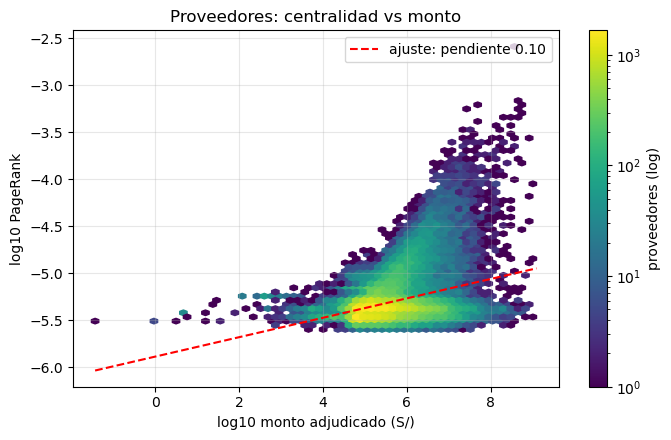

In [7]:
fig, ax = plt.subplots(figsize=(7, 4.5))
hb = ax.hexbin(x, y, gridsize=60, bins="log", cmap="viridis")
xs = np.linspace(x.min(), x.max(), 50)
ax.plot(xs, b0 + b1 * xs, "r--", label=f"ajuste: pendiente {b1:.2f}")
ax.set(xlabel="log10 monto adjudicado (S/)", ylabel="log10 PageRank", title="Proveedores: centralidad vs monto"); ax.legend()
plt.colorbar(hb, ax=ax, label="proveedores (log)")
mostrar_fig("pagerank_vs_monto")

- **Pendiente 0.10, R² 0.12:** el monto explica muy poco de la centralidad

- **"Más central que su monto"** (top 1% del residuo, 860 proveedores): adjudicaciones recurrentes a muchas entidades (mediana de 17); solo **0.6%** consorcios

- **"Más monto que centralidad"** (860): casi todos **consorcios** (**82.7%**) con una adjudicación grande a una sola entidad (mediana de 1 entidad, S/21.5M)

- Es la **misma población** que en `02_Clustering` atendía a las entidades cautivas: mucho dinero en una arista aislada

---
### **3. Centralidad por tipología (KMeans)**

In [8]:
def por_tipologia(d):
    return (d.groupby("tipologia")
             .agg(actores=("idx", "size"), pct_pr_med=("pct_pr", "median"), pct_hits_med=("pct_hits", "median"),
                  en_top_pr=("pct_pr", lambda s: int((s >= P_ALTO).sum())), en_top_hits=("pct_hits", lambda s: int((s >= P_ALTO).sum())))
             .round(3))

tip_ent, tip_prov = por_tipologia(ent), por_tipologia(prov)
display(tip_ent); display(tip_prov)

,actores,pct_pr_med,pct_hits_med,en_top_pr,en_top_hits
tipologia,,,,,
compra sin competencia,234,0.657,0.704,6,4
compradoras de obras,680,0.480,0.295,0,0
compradoras pequeñas,909,0.328,0.463,0,0
fuera del clustering (< 5 procesos),296,0.066,0.098,0,0
grandes diversificadas,873,0.826,0.786,24,26


,actores,pct_pr_med,pct_hits_med,en_top_pr,en_top_hits
tipologia,,,,,
contratistas de obras,1021,0.931,0.747,12,44
esporádico (fuera del clustering),72700,0.423,0.439,0,76
ganadores sin competencia,1650,0.889,0.813,13,13
grandes multicliente,2394,0.984,0.941,804,441
típicos de pocos clientes,8252,0.910,0.836,32,287


- **Proveedores:** los **grandes multicliente** concentran 804 de los 861 del top 1% de PageRank y 441 del de HITS

- **"Ganadores sin competencia"** (79% en Lima, 53% personas naturales): percentil mediano 0.89 en PageRank, pero solo 13 en el top 1%; ganan seguido, pero a pocas entidades

- **Esporádicos** (fuera del clustering): ninguno en el top 1% de PageRank, pero 76 en el de HITS (una sola venta a un gran hub de salud)

- **Entidades:** las **grandes diversificadas** son los hubs (24 de los 30 del top 1% de PageRank y 26 del de HITS); las **compradoras pequeñas** y **de obras**, las de menor centralidad

- **Convergencia con la Parte II:** centralidad y tipologías cuentan la misma historia; la novedad está en los que no encajan (§2)

---
### **4. Cautividad y centralidad (PQ1)**

- Mismo filtro (`n_procesos ≥ 5`) y umbral (`HHI ≥ 0.25`) que `02_Clustering`

- **Proveedor principal** de cada entidad: el de mayor monto

In [9]:
e5 = ent[ent.n_procesos >= MIN_PROC_ENT].copy()
e5["cautiva"] = (e5.hhi_proveedores >= UMBRAL_HHI).astype(int)
cautividad = (e5.groupby("cautiva").agg(entidades=("idx", "size"), pct_pr_med=("pct_pr", "median"), pct_hits_med=("pct_hits", "median"),
                                        grado_med=("grado", "median"), pct_en_gigante=("en_gigante", lambda s: 100 * s.mean()))
                .round(3))

top = (a.assign(monto=a.monto.fillna(0)).sort_values("monto", ascending=False).drop_duplicates("i")
        .rename(columns={"i": "idx_e", "monto": "monto_rel"}))
top["idx"] = top.j + n_e
principal = (e5[["idx", "cautiva"]].rename(columns={"idx": "idx_e"}).merge(top[["idx_e", "idx", "monto_rel"]], on="idx_e")
               .merge(prov[["idx", "nombre", "tipologia", "es_consorcio", "pct_pr", "pct_hits", "hits_rel", "cuota_billetera"]], on="idx"))
atiende = (principal.groupby("cautiva")
             .agg(entidades=("idx_e", "size"), pct_consorcio=("es_consorcio", lambda s: 100 * s.fillna(0).mean()),
                  pct_pr_med=("pct_pr", "median"), pct_hits_med=("pct_hits", "median"),
                  pct_hits_cero=("hits_rel", lambda s: 100 * (s < 1e-6).mean()), cuota_med=("cuota_billetera", "median"))
             .round(3))
display(cautividad); display(atiende)

,entidades,pct_pr_med,pct_hits_med,grado_med,pct_en_gigante
cautiva,,,,,
0,1889,0.674,0.647,35.0,99.100
1,807,0.293,0.329,8.0,92.689


,entidades,pct_consorcio,pct_pr_med,pct_hits_med,pct_hits_cero,cuota_med
cautiva,,,,,,
0,1889,50.556,0.737,0.452,44.097,0.059
1,807,67.286,0.729,0.141,73.234,0.125


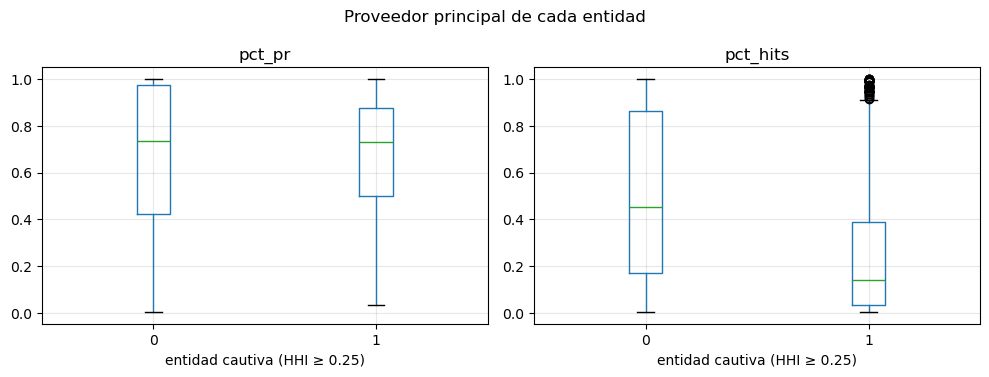

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for k_, c in enumerate(("pct_pr", "pct_hits")):
    principal.boxplot(column=c, by="cautiva", ax=ax[k_])
    ax[k_].set(title=c, xlabel="entidad cautiva (HHI ≥ 0.25)")
plt.suptitle("Proveedor principal de cada entidad")
mostrar_fig("proveedor_principal_cautivas")

- **Las cautivas son periféricas:** hub mediano en percentil 0.33 vs 0.65 de las no cautivas; grado mediano 8 vs 35; 7.3% fuera de la componente gigante (vs 0.9%)

- **Su proveedor principal no es del núcleo:**
  - El **73.2%** tiene authority = 0 (44.1% en las no cautivas)
  - El **67.3%** es consorcio (50.6%)
  - Su PageRank es parecido (percentil 0.73 en ambos grupos), pero su `cuota_billetera` mediana es el doble (0.125 vs 0.059): concentra la compra de pocas entidades

- **Respuesta a PQ1 (actores centrales):** la concentración del gasto en pocos proveedores **no** es dependencia de los proveedores centrales
  - Los centrales (HITS y PageRank alto) son los grandes multicliente que venden a entidades diversificadas
  - La cautividad es un fenómeno **local**: entidades chicas o de obras atadas a un proveedor (casi siempre consorcio) que no aparece en el resto de la red

---
### **5. Variación de los resultados**

In [11]:
variacion = pd.concat([
    tabla("a_grafo", "eleccion_peso").assign(parametro="peso (PageRank)", valor=lambda t: t.peso,
                                             resultado=lambda t: "Spearman con monto " + t.spearman_monto.round(2).astype(str)),
    tabla("b_pagerank", "sensibilidad_damping").query("tipo == 'proveedor'").assign(
        parametro="damping d", valor=lambda t: t.d.astype(str),
        resultado=lambda t: "Spearman vs 0.85 " + t.spearman_vs_085.round(3).astype(str) + ", top-20 " + t.top20_vs_085.round(2).astype(str)),
    pd.DataFrame([{"parametro": "percentil 'alto'", "valor": str(q),
                   "resultado": f"{int(((prov.pct_pr >= q) & (prov.pct_hits < q)).sum())} solo PageRank alto, "
                                f"{int(((prov.pct_pr < q) & (prov.pct_hits >= q)).sum())} solo HITS alto"} for q in RANGO_P_ALTO])
])[["parametro", "valor", "resultado"]]
variacion

,parametro,valor,resultado
0,peso (PageRank),binario,Spearman con monto 0.2
1,peso (PageRank),n_adj,Spearman con monto 0.26
2,peso (PageRank),log_monto,Spearman con monto 0.51
3,peso (PageRank),monto,Spearman con monto 0.86
1,damping d,0.5,"Spearman vs 0.85 0.987, top-20 0.9"
3,damping d,0.65,"Spearman vs 0.85 0.993, top-20 1.0"
5,damping d,0.75,"Spearman vs 0.85 0.997, top-20 1.0"
7,damping d,0.85,"Spearman vs 0.85 1.0, top-20 1.0"
9,damping d,0.9,"Spearman vs 0.85 0.998, top-20 0.9"
11,damping d,0.95,"Spearman vs 0.85 0.99, top-20 0.82"


- **Peso:** `monto` vuelve a PageRank un ranking de monto; `n_adj` y `log_monto` dan rankings parecidos

- **Damping:** estable entre 0.75 y 0.90; las conclusiones no dependen de d = 0.85

- **Percentil alto:** el número de divergentes cambia, pero su perfil (consorcios y locales vs. núcleo nacional) se mantiene

---
### **6. Casos concretos**

In [12]:
casos = pd.concat([
    prov.nlargest(1, "pr").assign(caso="proveedor de mayor PageRank"),
    prov.nlargest(1, "hits").assign(caso="authority principal"),
    p_.nlargest(1, "residuo").assign(caso="proveedor más central que su monto"),
    p_.nsmallest(1, "residuo").assign(caso="proveedor con más monto que centralidad"),
    ent.nlargest(1, "hits").assign(caso="hub principal"),
    e5[e5.cautiva == 1].nlargest(1, "pr").assign(caso="entidad cautiva más central")])
casos = casos[["caso", "nombre", "tipologia", "grado", "fuerza", "monto", "pct_pr", "pct_hits"]]
casos

,caso,nombre,tipologia,grado,fuerza,monto,pct_pr,pct_hits
65795,proveedor de mayor PageRank,GRUPO SANTA FE SOCIEDAD ANONIMA CERRADA - GRUPO SANTA FE S.A.C.,grandes multicliente,275,1704.0,3.555030e+08,1.000000,0.998431
65206,authority principal,DIAGNOSTICA PERUANA S.A.C.,grandes multicliente,109,572.0,4.083834e+08,0.999988,1.000000
65795,proveedor más central que su monto,GRUPO SANTA FE SOCIEDAD ANONIMA CERRADA - GRUPO SANTA FE S.A.C.,grandes multicliente,275,1704.0,3.555030e+08,1.000000,0.998431
16622,proveedor con más monto que centralidad,CONSORCIO EDIFICADOR SUR,esporádico (fuera del clustering),1,1.0,3.478837e+08,0.015160,0.980806
2190,hub principal,SEGURO SOCIAL DE SALUD,grandes diversificadas,1917,5046.0,7.487740e+09,0.999666,1.000000
1246,entidad cautiva más central,MUNICIPALIDAD DISTRITAL DE ILABAYA,grandes diversificadas,205,347.0,4.610573e+08,0.964238,0.949532


- **Grupo Santa Fe** (mayor PageRank y más central que su monto): 275 entidades, 1,704 adjudicaciones y S/355.5M; es el mismo actor en ambos casos

- **Diagnóstica Peruana** (authority principal): 109 entidades, 572 adjudicaciones y S/408.4M, casi todo a hospitales e institutos de salud

- **Consorcio Edificador Sur** (más monto que centralidad): S/347.9M en una sola adjudicación a una sola entidad

- **EsSalud** (hub principal): 1,917 proveedores, 5,046 adjudicaciones y S/7,488M

- **Municipalidad Distrital de Ilabaya** (entidad cautiva más central): 205 proveedores y percentil 0.96 de PageRank; cautiva por monto, no por falta de proveedores

---
### **7. Limitaciones y ética**

- **Señal, no acusación:** una centralidad alta o una dependencia fuerte describen la forma de la red, no una irregularidad; un proveedor único puede tener exclusividad técnica o geográfica legítima

- **Consorcios sin miembros:** la fuente no publica quién los integra; un grupo empresarial repartido en varios consorcios aparece como muchos nodos periféricos, y su centralidad real queda **subestimada**

- **Proveedores sin región propia:** se ubican por la región de sus clientes

- **La arista es la adjudicación**, no el pago: el 10.8% sin contrato vinculado sigue contando

- **Uso responsable:** los listados con nombres se publican como **perfiles para revisión** por los órganos de control, con la metodología al lado, nunca como ranking de sospechosos

---
### **8. Síntesis**

- **Grafo:** bipartito no dirigido entidad ↔ proveedor con peso `n_adj`; el dirigido E→P degenera en una suma de cuotas de billetera, que se conserva como medida de dependencia

- **PageRank** (Spark validado contra scipy y GraphFrames): estable para d entre 0.75 y 0.90; con d → 1 se vuelve la fuerza

- **HITS** (= SVD de rango 1): se concentra en el núcleo denso y es la medida que más se separa del volumen

- **Actores centrales:** los grandes multicliente y las grandes compradoras diversificadas, igual que las tipologías de KMeans

- **PQ1:** las entidades cautivas son periféricas y dependen de proveedores fuera del núcleo (sobre todo consorcios de un solo proceso); la concentración es **local**, no captura por los proveedores centrales

- **Aporte propio de esta parte:** el contraste centralidad vs monto aísla dos perfiles que el clustering mezcla
  - Proveedores recurrentes de bajo monto, con muchos clientes
  - Consorcios de alto monto con un solo cliente

---
### **9. Escritura de resultados**

In [13]:
web_scatter = p_.nlargest(3000, "fuerza")[["clave", "nombre", "tipologia", "es_consorcio", "grado", "monto",
                                           "pr", "hits", "pct_pr", "pct_hits", "residuo"]]
escritos = guardar_tablas({
    "correlaciones": corr.reset_index().rename(columns={"level_0": "sujeto", "level_1": "medida"}),
    "contraste_monto": contraste.reset_index(), "mas_central_que_monto": mas_central, "mas_monto_que_central": mas_monto,
    "por_tipologia": pd.concat({"entidad": tip_ent, "proveedor": tip_prov}).reset_index().rename(columns={"level_0": "sujeto"}),
    "cautividad": cautividad.reset_index(), "atienden_cautivas": atiende.reset_index(), "variacion": variacion,
    "casos": casos, "centralidad_web": web_scatter})

Escrito en 04_PageRank/temp/d_analisis/: correlaciones, contraste_monto, mas_central_que_monto, mas_monto_que_central, por_tipologia, cautividad, atienden_cautivas, variacion, casos, centralidad_web


#### a. Verificación

In [14]:
verificar_salidas(escritos)

OK: 10 tablas (parquet + json) | 2 figuras: pagerank_vs_monto, proveedor_principal_cautivas


---
### **10. Cerrar sesión**

In [15]:
spark.stop()